# Handling Imports

In [11]:
import pandas as pd

# Importing and preprocessing data

In [12]:
colnames=['reading']
data = pd.read_csv('302.csv',names=colnames)
data.head()

,reading
0,2193.96
1,2195.85
2,2195.70
3,2201.08
4,2202.39


In [13]:
data.shape

(3828, 1)

In [14]:
import numpy as np
x= np.arange(0,3828)
x.shape

(3828,)

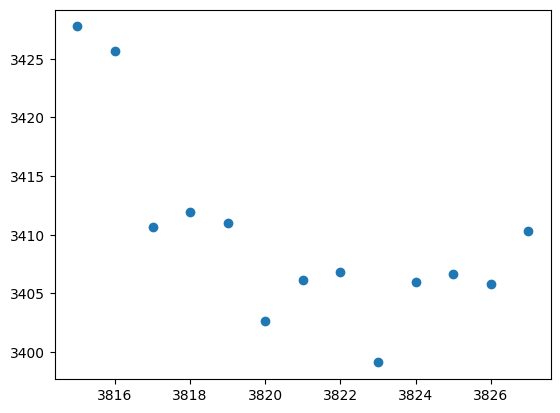

In [15]:
import matplotlib.pyplot as plt
st_batch = 3815
batch = 3830
plt.scatter(x[st_batch:batch], data[st_batch:batch])
plt.show()

lets record a data point..... term it as calibration point
on bending the value of strain increases...and reaches a peak....
Now if i term the difference between calibration pont and peak as change and then if the there is a downfall of value more than 1/4 of change we count it as a cycle. now , we keep counting it as same cycle until it start increasing that point, if it falls we make the point as low point of cycle. onve it goes above low point we restart loop with low point as new calibration point..... now if if the change is less then 1/4th of original value then we assume that there is no cycle its just a human error.

In [16]:
def moving_avarage_smoothing(X,k):
    S = np.zeros(X.shape[0])
    for t in range(X.shape[0]):
        if t < k:
            S[t] = np.mean(X[:t+1])
        else:
            S[t] = np.sum(X[t-k:t])/k
    return S

def exponential_smoothing(X,α):
    S = np.zeros(X.shape[0])
    S[0] = X[0]
    for t in range(1,X.shape[0]):
        S[t] = α * X[t-1] + (1- α) * S[t-1]
    return S

def double_exponential_smoothing(X,α,β):
    S,A,B = (np.zeros( X.shape[0] ) for i in range(3))
    S[0] = X[0]
    B[0] = X[1] - X[0]
    for t in range(1,X.shape[0]):
        A[t] = α * X[t] + (1- α) * S[t-1]
        B[t] = β * (A[t] - A[t-1]) + (1 - β) * B[t-1]
        S[t] = A[t] + B[t]
    return S

def triple_exponential_smoothing(X,L,α,β,γ,ϕ):

    def sig_ϕ(ϕ,m):
        return np.sum(np.array([np.power(ϕ,i) for i in range(m+1)]))

    C, S, B, F = (np.zeros( X.shape[0] ) for i in range(4))
    S[0], F[0] = X[0], X[0]
    B[0] = np.mean( X[L:2*L] - X[:L] ) / L
    m = 12
    sig_ϕ = sig_ϕ(ϕ,m)
    for t in range(1, X.shape[0]):
        S[t] = α * (X[t] - C[t % L]) + (1 - α) * (S[t-1] + ϕ * B[t-1])
        B[t] = β * (S[t] - S[t-1]) + (1-β) * ϕ * B[t-1]
        C[t % L] = γ * (X[t] - S[t]) + (1 - γ) * C[t % L]
        F[t] = S[t] + sig_ϕ * B[t] + C[t % L]
    return S

In [17]:
#smoothing techiniques
time_series = np.array(data['reading'])
# data3 = moving_avarage_smoothing(time_series,10)
# data4 = exponential_smoothing(time_series,0.3)
# data5 = double_exponential_smoothing(time_series,0.01,0.07)
data6 = triple_exponential_smoothing(time_series,12,0.2,0.8,0.1,0.5)


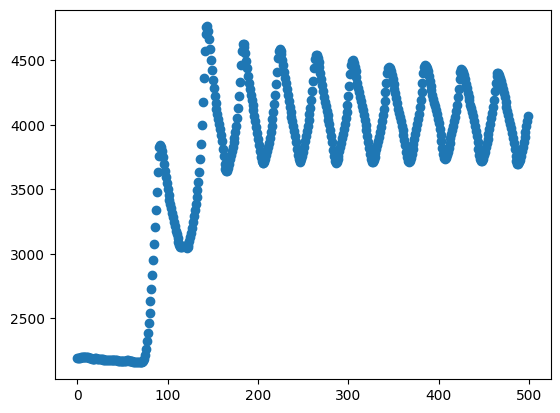

In [18]:
# from scipy.ndimage import gaussian_filter1d
# data2 = gaussian_filter1d(data[3815:3830], 7)
# plt.scatter(x[1526:2052], data3[1526:2052])
# plt.show()
# plt.scatter(x[1526:2052], data4[1526:2052])
# plt.show()
# plt.scatter(x[1526:2052], data5[1526:2052])
# plt.show()
plt.scatter(x[:500], data6[:500])
plt.show()

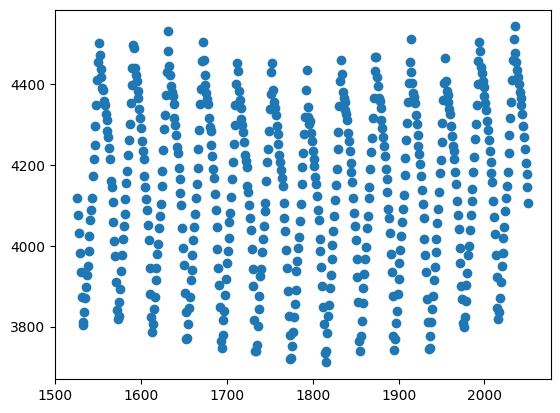

In [19]:
plt.scatter(x[1526:2052], data[1526:2052])
plt.show()

In [20]:
from cydets.algorithm import detect_cycles
cycles = detect_cycles(pd.Series(data3))
from cydets.algorithm import detect_cycles
cycles1 = detect_cycles(pd.Series(data4))
from cydets.algorithm import detect_cycles
cycles2 = detect_cycles(pd.Series(data5))
from cydets.algorithm import detect_cycles
cycles3 = detect_cycles(pd.Series(data6))
print(cycles[1:])
print(cycles1[1:])
print(cycles2[1:])
print(cycles3[1:])

NameError: name 'data3' is not defined

# From above we can conclude triple exponential is best fitting the data

now lets move to real time..., taking data unput in batches of 50 at a time and implementing smoothing

In [21]:
import pandas as pd
batch_size= 30

colnames=['reading']
data = pd.read_csv('302.csv',names=colnames)
import numpy as np
x= np.arange(0,30)
x1= np.arange(0,5000)

def triple_exponential_smoothing(X,L,α,β,γ,ϕ):

    def sig_ϕ(ϕ,m):
        return np.sum(np.array([np.power(ϕ,i) for i in range(m+1)]))

    C, S, B, F = (np.zeros( X.shape[0] ) for i in range(4))
    S[0], F[0] = X[0], X[0]
    B[0] = np.mean( X[L:2*L] - X[:L] ) / L
    m = 12
    sig_ϕ = sig_ϕ(ϕ,m)
    for t in range(1, X.shape[0]):
        S[t] = α * (X[t] - C[t % L]) + (1 - α) * (S[t-1] + ϕ * B[t-1])
        B[t] = β * (S[t] - S[t-1]) + (1-β) * ϕ * B[t-1]
        C[t % L] = γ * (X[t] - S[t]) + (1 - γ) * C[t % L]
        F[t] = S[t] + sig_ϕ * B[t] + C[t % L]
    return S

smooth_data = triple_exponential_smoothing(time_series,12,0.2,0.8,0.1,0.5)
from cydets.algorithm import detect_cycles
half_cycles = detect_cycles(pd.Series(smooth_data))
half_cycles = half_cycles[1:]
#removing all cycles with value of duration less than 5
half_cycles = half_cycles[half_cycles['duration'] > 10]
half_cycles = half_cycles[half_cycles['duration'] < 500]
print("STRAIN CYCLE : " , half_cycles.shape[0]/2)
# half_cycls

# half_cycles[:1]['t_start']

half_cycles[:1]['t_start']
half_cycles.shape
# for i in range(0,half_cycles.shape[0]):
#     print(half_cycles[i:i+1]['t_start'])
#     print(half_cycles[i:i+1]['t_end'])
#     plt.scatter(x1[int(half_cycles[i:i+1]['t_start']):int(half_cycles[i:i+1]['t_end'])], data6[int(half_cycles[i:i+1]['t_start']):int(half_cycles[i:i+1]['t_end'])])
#     plt.show()

STRAIN CYCLE :  71.5


(143, 5)

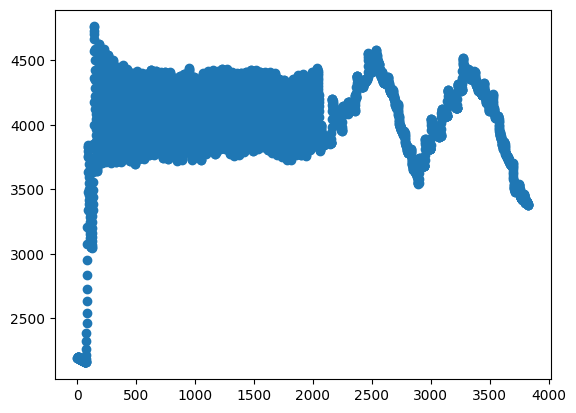

array([  40.68597591,  813.71951814,  895.09146995,  854.40549404,
        813.71951814,  732.34756632,  691.66159042,  773.03354223,
        691.66159042,  650.97561451,  650.97561451,  650.97561451,
        691.66159042,  610.2896386 ,  650.97561451,  650.97561451,
        610.2896386 ,  732.34756632,  650.97561451,  569.6036627 ,
        732.34756632,  610.2896386 ,  610.2896386 ,  610.2896386 ,
        569.6036627 ,  569.6036627 ,  650.97561451,  610.2896386 ,
        610.2896386 ,  610.2896386 ,  610.2896386 ,  569.6036627 ,
        691.66159042,  650.97561451,  569.6036627 ,  569.6036627 ,
        610.2896386 ,  610.2896386 ,  569.6036627 ,  610.2896386 ,
        569.6036627 ,  569.6036627 ,  610.2896386 ,  650.97561451,
        528.91768679,  569.6036627 ,  691.66159042,  162.74390363,
         81.37195181,  244.11585544,   81.37195181,   40.68597591,
         40.68597591,   40.68597591,  122.05792772,  650.97561451,
         40.68597591,  162.74390363,   40.68597591,   40.68597

In [22]:
# import rainflow
# rainflow.count_cycles(data['reading'])
import fatpack
import matplotlib.pyplot as plt
# Generate a data series
import numpy as np

rainflow_ranges = fatpack.find_rainflow_ranges(data6)
plt.scatter(x1[:3828], data6)
plt.show()

rainflow_ranges
